# **A COMMITTEE MACHINE LEARNING FRAMEWORK FOR HIGH-PRECISION PREDICTION OF CO₂ STORAGE CAPACITY**

## **Author**

```python
Andika Sukmana | andikasukmana331@gmail.com 

student of Geophysical Engineering at Institut Teknologi Bandung, Indonesia.

### **Reference**

```python 

  - type: article
   
    title: "Committee machine learning: A breakthrough in the precise prediction of CO2 storage mass and oil production volumes in unconventional reservoirs"
   
    authors: Davoodi, S., Vo Thanh, H., Wood, D. A., Mehrad, M., Al-Shargabi, M., & Rukavishnikov, V. S.
   
    journal: "Geoenergy Science and Engineering"
   
    year: 2025
   
    doi: "https://10.1016/j.geoen.2024.213533"

  - type: dataset
    
    title: "Reservoir simulation data from the paper above"
    
    authors:
      - name: Davoodi, S., Vo Thanh, H., Wood, D. A., Mehrad, M., Al-Shargabi, M., & Rukavishnikov, V. S.
    
    year: 2025
    
    url: "https://10.1016/j.geoen.2024.213533"

## **Abstract**

```
The increasing urgency of global decarbonization has accelerated the development of Carbon, Capture, Utilization, and Storage (CCUS) technologies to reduce gas emissions while maintaining energy security. Among these approaches, CO₂ Enhanced Oil Recovery (EOR) offers a strategic pathway by simultaneously enabling long term CO₂ sequestration and improving hydrocarbon recovery. However, accurately predicting CO₂ storage capacity and cumulative oil production remains challenging due to the complex and nonlinear characteristics of reservoirs, while conventional reservoir simulation is computationally intensive and timeconsuming. This study investigates how Machine Learning (ML) can address the challenges of predicting CO₂ storage capacity and cumulative oil production in reservoirs. The proposed Committee Machine Learning Gaussian Process Regression (CML-GPR) framework integrates Random Forest (RF), Generalized Regression Neural Network (GRNN), and Multi-Layer Extreme Learning Machine (MELM) to improve prediction accuracy and model robustness compared with conventional individual machine learning approaches. The model was developed using 21,193 simulation cases refined through Mahalanobis distance-based outlier detection and demonstrated superior predictive performance compared with individual machine learning models. On testing datasets, the framework achieved R² values of 0.9896 and 0.8118, with RMSE values of 1.15 million metric tons for CO₂ storage mass prediction and 5.77 million barrels for cumulative oil production prediction. We examined the feasibility of ML application for implementation in Indonesia, particularly the Minas Field in the Rokan Block. Its substantial remaining oil resources, extensive production history, established infrastructure, and high potential for CO₂ EOR and carbon storage make it an attractive candidate for CCUS deployment. By enabling rapid estimation of CO₂ storage potential and oil recovery without extensive simulation campaigns, the proposed framework can support more efficient CCUS project evaluation and decision-making. This implementation offers technical, economic, and environmental benefits, contributing to EOR, accelerated reservoir assessment, and permanent CO₂ sequestration, thereby supporting Indonesia Net Zero Emission commitments. 

# **Import Library**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ExpSineSquared, RationalQuadratic, DotProduct
from sklearn.metrics import r2_score, mean_squared_error
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv
from scipy.stats import norm
from pycaret.datasets import get_data
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, WhiteKernel
from sklearn.neural_network import MLPRegressor
import json
import time
# import shap

# **1. Import Libraries and Load Dataset**

In [2]:
data = 'data.xlsx'
df = pd.read_excel(data)
df.head()

,BHP (psi),Area (ft2),INJRATE (ft3/day),POR,Perm (md),THICKNESS (ft),Depth (ft),Sorg,Sorw,CO2 storage (ton),Cummulative oil production (bbl)
0,374.7369,168314.629800,23700000,0.382373,141.45,20.45989,4031.438,0.166564,0.248,36800000,335746000.0
1,1593.7880,5450.697327,16300000,0.202140,308.10,31.08438,6029.060,0.191255,0.261,31900000,105767000.0
2,1964.7950,206913.527300,15300000,0.383936,469.70,43.41698,6028.688,0.172631,0.313,25000000,533112100.0
3,896.1419,116876.314900,9581759,0.258218,106.10,43.87388,3545.230,0.118374,0.368,11300000,134440000.0
4,1176.1250,49294.625810,1326234,0.266773,409.10,43.65648,4913.683,0.106439,0.278,5980000,127985300.0


In [3]:
df.describe()

,BHP (psi),Area (ft2),INJRATE (ft3/day),POR,Perm (md),THICKNESS (ft),Depth (ft),Sorg,Sorw,CO2 storage (ton),Cummulative oil production (bbl)
count,21193.000000,21193.000000,2.119300e+04,21193.000000,21193.000000,21193.000000,21193.000000,21193.000000,21193.000000,2.119300e+04,2.119300e+04
mean,1079.798578,101035.230659,1.299099e+07,0.209890,251.602812,27.037837,4995.190536,0.149934,0.304522,1.970826e+07,1.732959e+08
std,531.563747,77035.131459,6.921643e+06,0.109795,145.059106,13.257623,861.471371,0.028878,0.060678,1.132829e+07,1.328281e+08
min,150.296100,1505.655390,1.000454e+06,0.020002,0.050000,4.002147,3500.416000,0.100010,0.200000,4.040000e+02,2.152518e+02
25%,623.849700,37433.216250,6.946381e+06,0.114806,126.300000,15.646900,4246.733000,0.124871,0.252000,1.000000e+07,6.756514e+07
50%,1084.166000,80911.886750,1.310000e+07,0.209123,252.550000,27.024870,4993.821000,0.150072,0.305000,1.960000e+07,1.449951e+08
75%,1541.216000,149117.938300,1.900000e+07,0.305583,373.750000,38.463650,5740.560000,0.174809,0.356000,2.890000e+07,2.494550e+08
max,1999.555000,353294.489300,2.500000e+07,0.399977,500.000000,49.999740,6499.987000,0.200000,0.410000,4.690000e+07,8.346855e+08


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21193 entries, 0 to 21192
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BHP (psi)                         21193 non-null  float64
 1   Area (ft2)                        21193 non-null  float64
 2   INJRATE (ft3/day)                 21193 non-null  int64  
 3   POR                               21193 non-null  float64
 4   Perm (md)                         21193 non-null  float64
 5   THICKNESS (ft)                    21193 non-null  float64
 6   Depth (ft)                        21193 non-null  float64
 7   Sorg                              21193 non-null  float64
 8   Sorw                              21193 non-null  float64
 9   CO2 storage (ton)                 21193 non-null  int64  
 10  Cummulative oil production (bbl)  21193 non-null  float64
dtypes: float64(9), int64(2)
memory usage: 1.8 MB


In [5]:
df = get_data('dataw',profile=True)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 62.37it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# **2. Data Preprocessing and EDA**

### **2.1 Remove the missing values**

In [6]:
df.isnull().sum()

BHP (psi)                           0
Area (ft2)                          0
INJRATE (ft3/day)                   0
POR                                 0
Perm (md)                           0
THICKNESS (ft)                      0
Depth (ft)                          0
Sorg                                0
Sorw                                0
CO2 storage (ton)                   0
Cummulative oil production (bbl)    0
dtype: int64

In [7]:
df.dropna(inplace=True)

### **2.2 Heatmap**

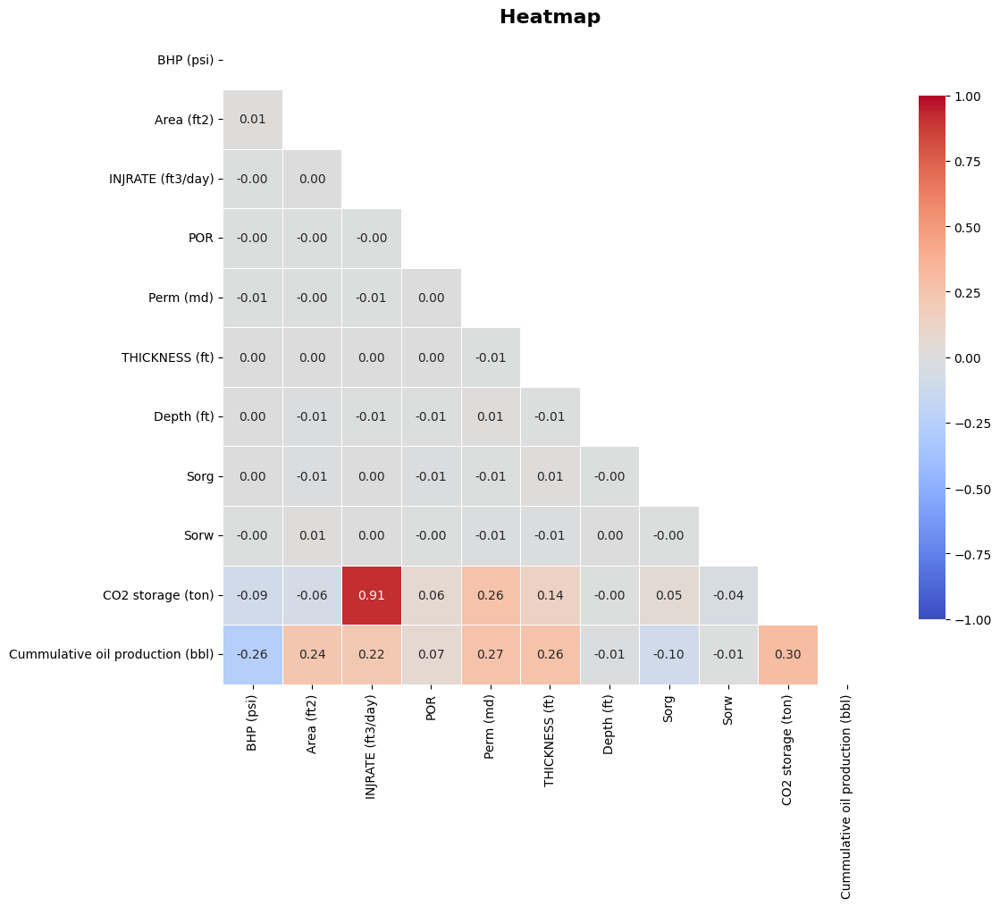

In [8]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,                
    annot=True,               
    fmt='.2f',                
    cmap='coolwarm',          
    vmin=-1, vmax=1,          
    square=True,              
    linewidths=0.5,           
    cbar_kws={"shrink": 0.8}, 
    annot_kws={'size': 10}    
)

plt.title('Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### **2.3 Pairplot**

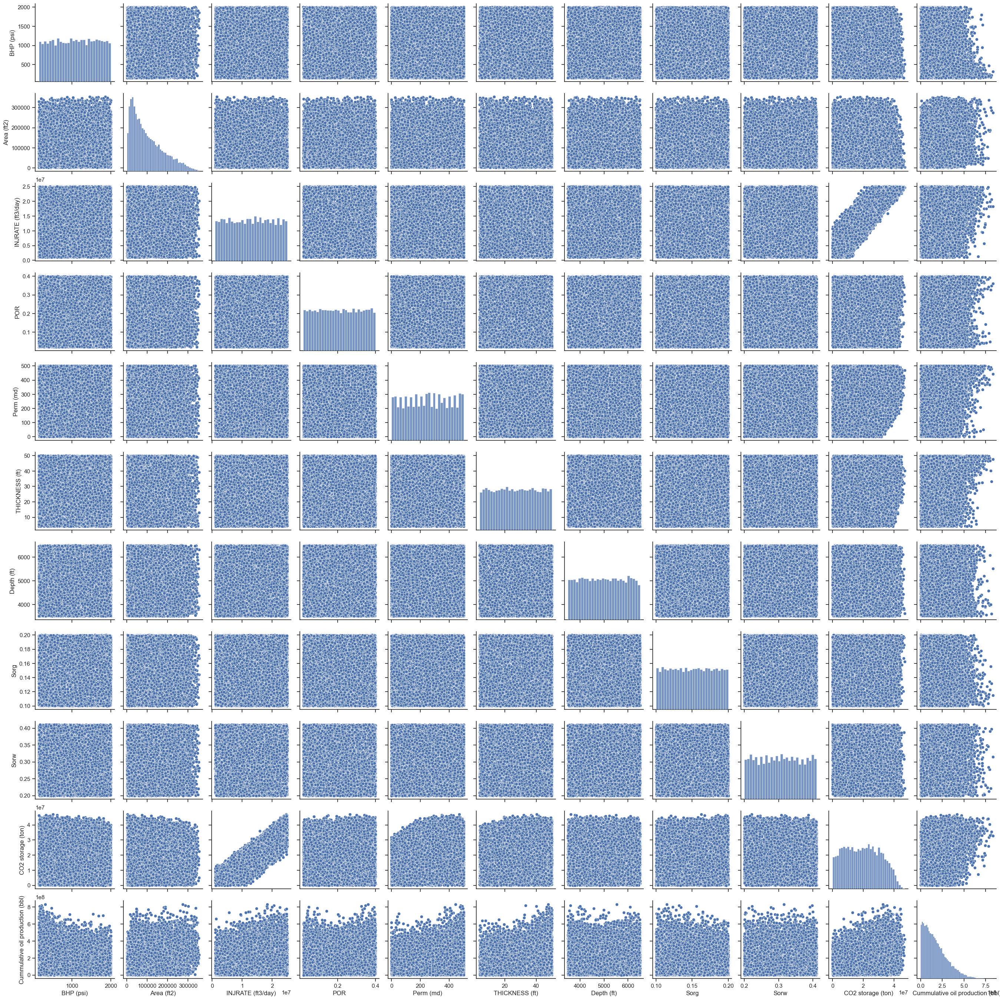

In [9]:
sns.set(style="ticks")
sns.pairplot(df)
plt.show()

### **2.4 Split Data**

In [10]:
input_cols = [
    'BHP (psi)', 'Area (ft2)', 'INJRATE (ft3/day)',
    'POR', 'Perm (md)', 'THICKNESS (ft)',
    'Depth (ft)', 'Sorg', 'Sorw'
]

target_cols = [
    'CO2 storage (ton)',
    'Cumulative oil production (bbl)'
]

target_name = 'CO2 storage (ton)'

X = df[input_cols].values
y = df[target_name].values

feature_names = input_cols

print(f"Dataset shape: {df.shape}")
print(f"Fitur input: {feature_names}")
print(f"Target dipilih: {target_name}")
print(f"Jumlah data: {len(X)}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Data latih mentah: {X_train.shape[0]}, Data uji mentah: {X_test.shape[0]}")

Dataset shape: (21193, 11)
Fitur input: ['BHP (psi)', 'Area (ft2)', 'INJRATE (ft3/day)', 'POR', 'Perm (md)', 'THICKNESS (ft)', 'Depth (ft)', 'Sorg', 'Sorw']
Target dipilih: CO2 storage (ton)
Jumlah data: 21193
Data latih mentah: 16954, Data uji mentah: 4239


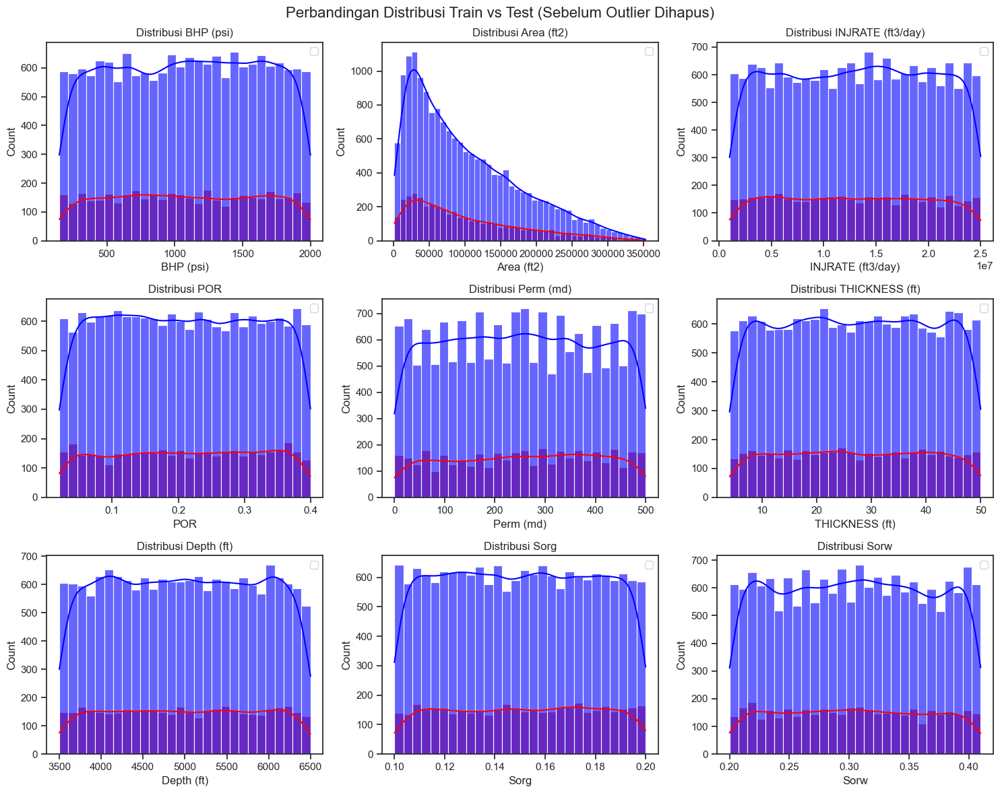

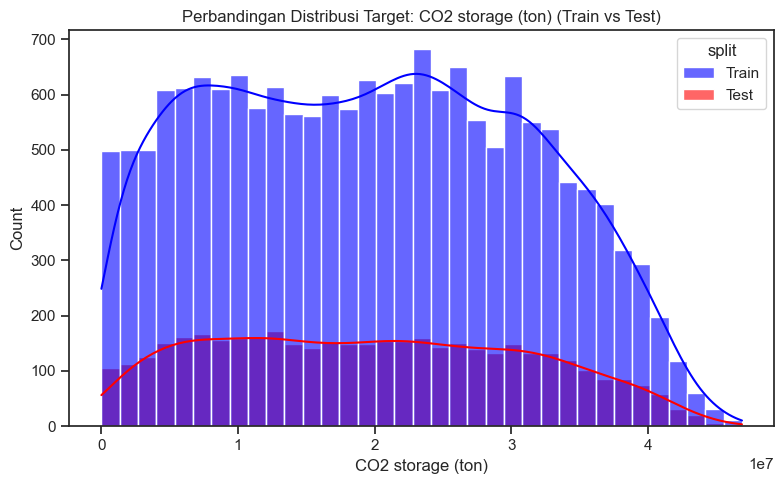

In [11]:
df_train_vs_test = pd.DataFrame(
    np.vstack([X_train, X_test]),
    columns=feature_names
)
df_train_vs_test['split'] = ['Train'] * len(X_train) + ['Test'] * len(X_test)

df_target_split = pd.DataFrame(
    np.hstack([y_train, y_test]),
    columns=[target_name]
)
df_target_split['split'] = ['Train'] * len(y_train) + ['Test'] * len(y_test)

# Histogram features
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(feature_names):
    sns.histplot(data=df_train_vs_test, x=col, hue='split', kde=True, 
                 alpha=0.6, ax=axes[i], palette=['blue', 'red'])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].legend()
plt.suptitle('Perbandingan Distribusi Train vs Test (Sebelum Outlier Dihapus)', fontsize=16)
plt.tight_layout()
plt.show()

# Histogram target
plt.figure(figsize=(8, 5))
sns.histplot(data=df_target_split, x=target_name, hue='split', kde=True, 
             alpha=0.6, palette=['blue', 'red'])
plt.title(f'Perbandingan Distribusi Target: {target_name} (Train vs Test)')
plt.tight_layout()
plt.show()

### **2.5 Outlier Detection**

In [12]:
def detect_outliers_mahalanobis(X_train, y_train, threshold_factor=3.0):
    if len(X_train) > 5000:
        indices = np.random.choice(len(X_train), 5000, replace=False)
        X_sample = X_train[indices]
        y_sample = y_train[indices]
    else:
        X_sample = X_train
        y_sample = y_train
    
    kernel = 1.0 * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-3)
    gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42)
    gpr.fit(X_sample, y_sample)
    
    # Predict for the entire training data
    y_pred = gpr.predict(X_train)
    
    residuals = y_train - y_pred
    mean_res = np.mean(residuals)
    std_res = np.std(residuals)
    # Avoid std = 0
    if std_res < 1e-12:
        std_res = 1e-12
    md = np.abs(residuals - mean_res) / std_res
    threshold = threshold_factor * np.mean(md)
    outliers = md > threshold
    return outliers, md, threshold

In [13]:
outliers_train, md_vals, threshold = detect_outliers_mahalanobis(X_train, y_train)
print(f"Jumlah outlier: {np.sum(outliers_train)}")

X_train_clean = X_train[~outliers_train]
y_train_clean = y_train[~outliers_train]
print(f"Data latih setelah outlier: {len(X_train_clean)}")

Jumlah outlier: 324
Data latih setelah outlier: 16630


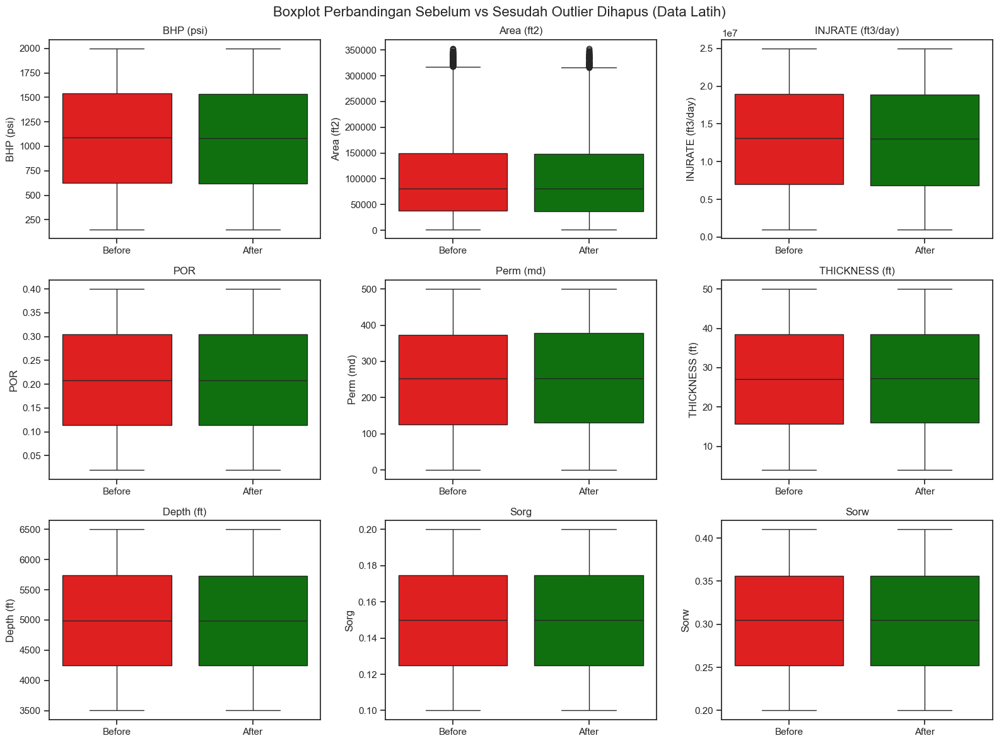

In [14]:
df_before = pd.DataFrame(X_train, columns=feature_names)
df_before['status'] = 'Before'
df_before[target_name] = y_train

df_after = pd.DataFrame(X_train_clean, columns=feature_names)
df_after['status'] = 'After'
df_after[target_name] = y_train_clean

df_compare = pd.concat([df_before, df_after], ignore_index=True)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(feature_names):
    sns.boxplot(data=df_compare, x='status', y=col, palette=['red', 'green'], ax=axes[i])
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')
plt.suptitle('Boxplot Perbandingan Sebelum vs Sesudah Outlier Dihapus (Data Latih)', fontsize=16)
plt.tight_layout()
plt.show()

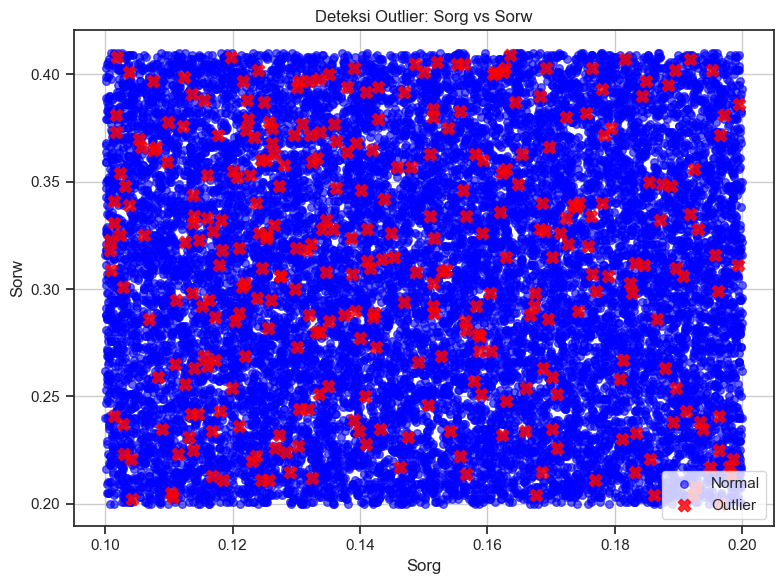

In [15]:
feat1 = 'Sorg'
feat2 = 'Sorw'
idx1 = feature_names.index(feat1)
idx2 = feature_names.index(feat2)

plt.figure(figsize=(8, 6))
plt.scatter(X_train[~outliers_train, idx1], X_train[~outliers_train, idx2],
            c='blue', label='Normal', alpha=0.6, s=30)
plt.scatter(X_train[outliers_train, idx1], X_train[outliers_train, idx2],
            c='red', label='Outlier', alpha=0.8, s=80, marker='X')
plt.xlabel(feat1)
plt.ylabel(feat2)
plt.title(f'Deteksi Outlier: {feat1} vs {feat2}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

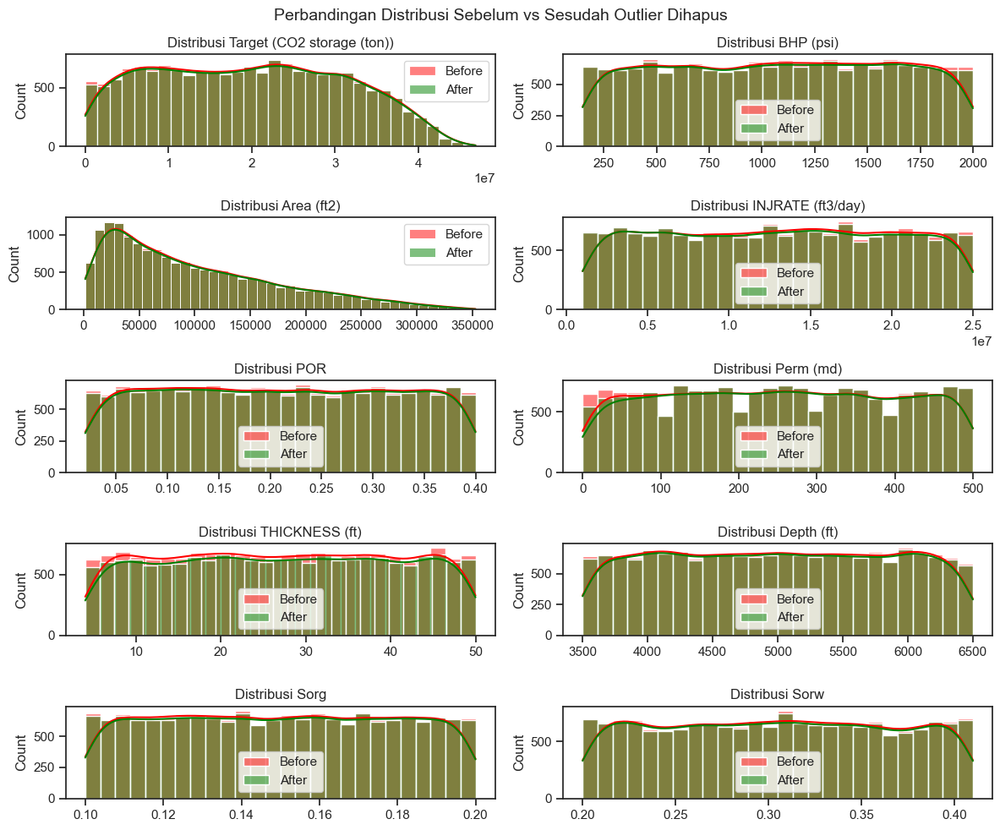

In [16]:
fig, axes = plt.subplots(5, 2, figsize=(12, 10))
# Target
sns.histplot(y_train, color='red', alpha=0.5, kde=True, label='Before', ax=axes[0,0])
sns.histplot(y_train_clean, color='green', alpha=0.5, kde=True, label='After', ax=axes[0,0])
axes[0,0].set_title(f'Distribusi Target ({target_name})')
axes[0,0].legend()

for ax, col in zip([axes[0,1], axes[1,0], axes[1,1], axes[2,0], axes[2,1], axes[3,0], axes[3,1], axes[4,0], axes[4,1]],
                   ['BHP (psi)', 'Area (ft2)', 'INJRATE (ft3/day)', 'POR', 'Perm (md)', 'THICKNESS (ft)', 'Depth (ft)', 'Sorg', 'Sorw']):
    idx = feature_names.index(col)
    sns.histplot(X_train[:, idx], color='red', alpha=0.5, kde=True, label='Before', ax=ax)
    sns.histplot(X_train_clean[:, idx], color='green', alpha=0.5, kde=True, label='After', ax=ax)
    ax.set_title(f'Distribusi {col}')
    ax.legend()

plt.suptitle('Perbandingan Distribusi Sebelum vs Sesudah Outlier Dihapus', fontsize=14)
plt.tight_layout()
plt.show()

### **2.6 Normalization**

In [17]:
scaler_X = MinMaxScaler(feature_range=(-1, 1))
scaler_y = MinMaxScaler(feature_range=(-1, 1))

X_train_scaled = scaler_X.fit_transform(X_train_clean)
X_test_scaled = scaler_X.transform(X_test)  # parameter dari data latih bersih

y_train_scaled = scaler_y.fit_transform(y_train_clean.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

print("\nNormalisasi selesai.")
print(f"Dimensi X_train_scaled: {X_train_scaled.shape}")
print(f"Dimensi X_test_scaled: {X_test_scaled.shape}")

y_train_orig = y_train_clean
y_test_orig = y_test


Normalisasi selesai.
Dimensi X_train_scaled: (16630, 9)
Dimensi X_test_scaled: (4239, 9)


In [18]:
# Make a DataFrame for the data before normalization (raw)
df_before_norm = pd.DataFrame(X_train_clean, columns=feature_names)
df_before_norm['status'] = 'Before Normalization (Raw)'

# Make a DataFrame for the data after normalization (scaled)
df_after_norm = pd.DataFrame(X_train_scaled, columns=feature_names)
df_after_norm['status'] = 'After Normalization (Scaled)'

# Gabungkan
df_compare_norm = pd.concat([df_before_norm, df_after_norm], ignore_index=True)

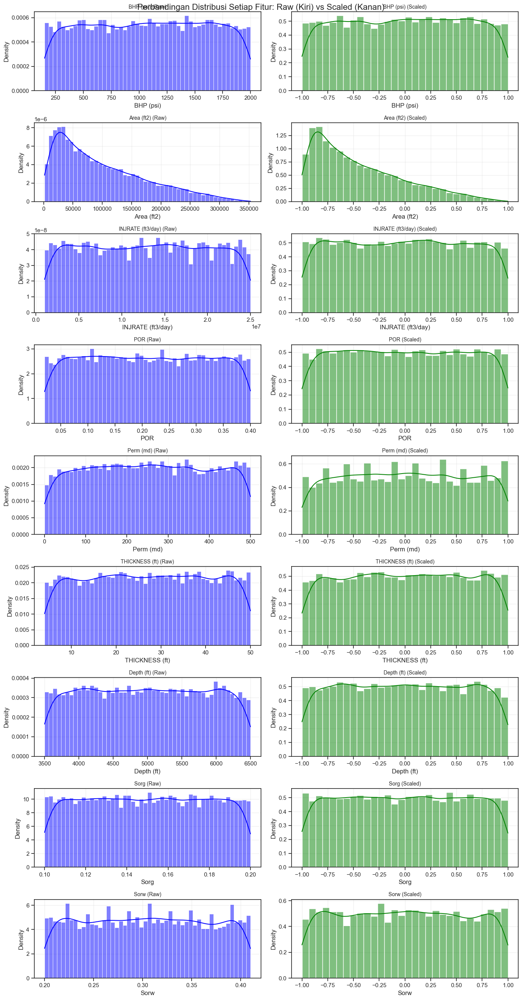

In [19]:
n_features = len(feature_names)
fig, axes = plt.subplots(n_features, 2, figsize=(14, n_features * 3))

for i, col in enumerate(feature_names):
    # Left column: Raw (Original)
    sns.histplot(data=df_before_norm, x=col, kde=True, color='blue', 
                 ax=axes[i, 0], stat='density', bins=50)
    axes[i, 0].set_title(f'{col} (Raw)', fontsize=10)
    axes[i, 0].grid(True, alpha=0.3)
    
    # Right column: Scaled
    sns.histplot(data=df_after_norm, x=col, kde=True, color='green', 
                 ax=axes[i, 1], stat='density', bins=30)
    axes[i, 1].set_title(f'{col} (Scaled)', fontsize=10)
    axes[i, 1].grid(True, alpha=0.3)

plt.suptitle('Perbandingan Distribusi Setiap Fitur: Raw (Kiri) vs Scaled (Kanan)', fontsize=16)
plt.tight_layout()
plt.show()

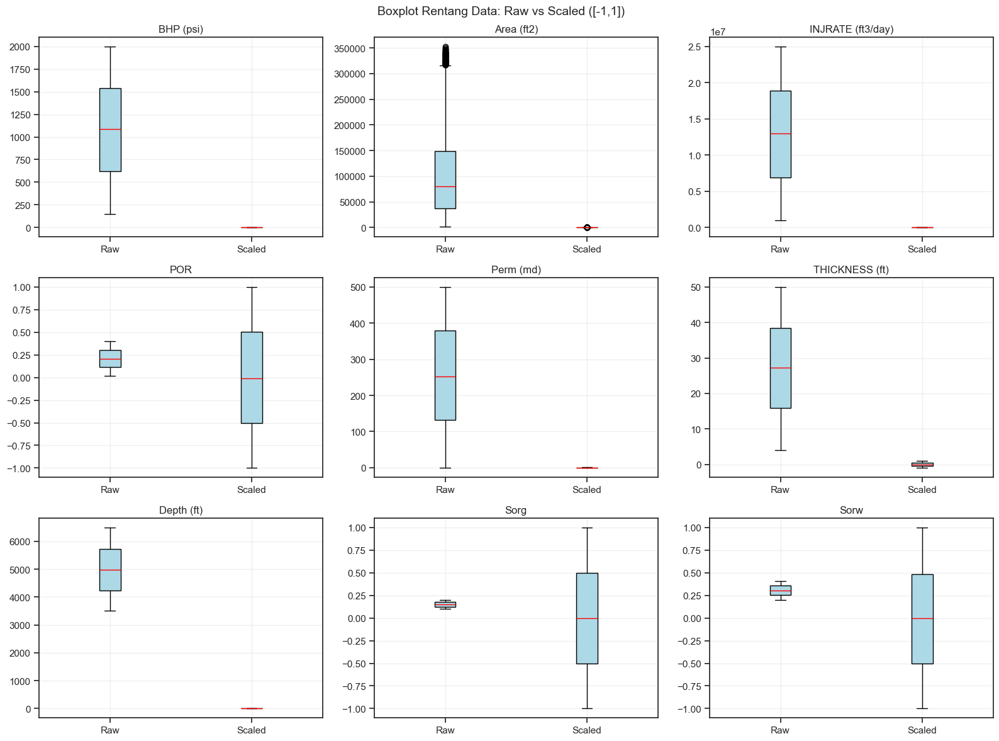

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(feature_names):
    data_before = df_before_norm[col]
    data_after = df_after_norm[col]
    
    bp = axes[i].boxplot([data_before, data_after], 
                         labels=['Raw', 'Scaled'],
                         patch_artist=True,
                         boxprops=dict(facecolor='lightblue'),
                         medianprops=dict(color='red'),
                         whiskerprops=dict(color='black'),
                         capprops=dict(color='black'))
    axes[i].set_title(f'{col}')
    axes[i].grid(True, alpha=0.3)
    
plt.suptitle('Boxplot Rentang Data: Raw vs Scaled ([-1,1])', fontsize=14)
plt.tight_layout()
plt.show()

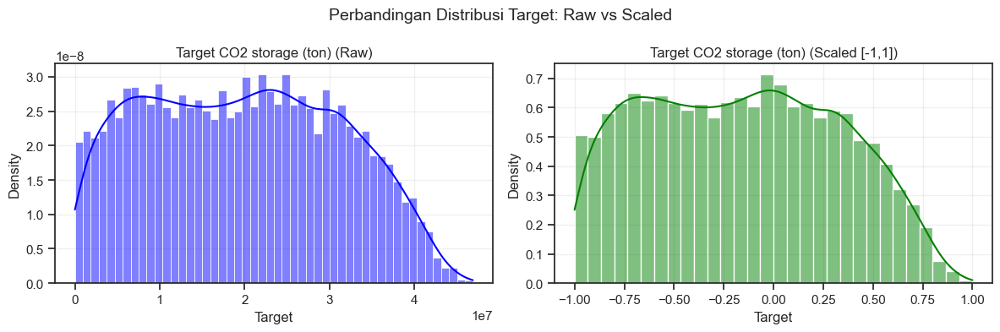

In [21]:
df_target_before = pd.DataFrame({'Target': y_train_clean, 'Status': 'Raw'})
df_target_after = pd.DataFrame({'Target': y_train_scaled, 'Status': 'Scaled'})
df_target_all = pd.concat([df_target_before, df_target_after], ignore_index=True)

# Plotting the target distributions before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Raw target
sns.histplot(data=df_target_before, x='Target', kde=True, color='blue', 
             ax=axes[0], stat='density', bins=50)
axes[0].set_title(f'Target {target_name} (Raw)')
axes[0].grid(True, alpha=0.3)

sns.histplot(data=df_target_after, x='Target', kde=True, color='green', 
             ax=axes[1], stat='density', bins=30)
axes[1].set_title(f'Target {target_name} (Scaled [-1,1])')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Perbandingan Distribusi Target: Raw vs Scaled', fontsize=14)
plt.tight_layout()
plt.show()

# **3. Tune the ML Model**

In [22]:
class MultiLayerELM:
    def __init__(self, hidden_layers=[6,6,7], activation='sigmoid', ridge=0.1, random_state=42):
        self.hidden_layers = hidden_layers
        self.activation = activation
        self.ridge = ridge
        self.random_state = random_state
        np.random.seed(random_state)
        self.weights = []
        self.biases = []
        self.beta = None
    
    def _activation_func(self, x):
        if self.activation == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(x, -500, 500)))  # hindari overflow
        elif self.activation == 'relu':
            return np.maximum(0, x)
        else:  # tanh
            return np.tanh(x)
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        
        w1 = np.random.uniform(-1, 1, (n_features, self.hidden_layers[0]))
        b1 = np.random.uniform(-1, 1, (1, self.hidden_layers[0]))
        H1 = self._activation_func(np.dot(X, w1) + b1)
        
        w2 = np.random.uniform(-1, 1, (self.hidden_layers[0], self.hidden_layers[1]))
        b2 = np.random.uniform(-1, 1, (1, self.hidden_layers[1]))
        H2 = self._activation_func(np.dot(H1, w2) + b2)
        
        w3 = np.random.uniform(-1, 1, (self.hidden_layers[1], self.hidden_layers[2]))
        b3 = np.random.uniform(-1, 1, (1, self.hidden_layers[2]))
        H3 = self._activation_func(np.dot(H2, w3) + b3)
        
        H = np.hstack([H3, np.ones((n_samples, 1))])
        
        HtH = H.T @ H
        HtH_reg = HtH + self.ridge * np.eye(HtH.shape[0])
        self.beta = np.linalg.inv(HtH_reg) @ H.T @ y
        
        # Simpan bobot untuk prediksi
        self.weights = [w1, w2, w3]
        self.biases = [b1, b2, b3]
    
    def predict(self, X):
        H1 = self._activation_func(np.dot(X, self.weights[0]) + self.biases[0])
        H2 = self._activation_func(np.dot(H1, self.weights[1]) + self.biases[1])
        H3 = self._activation_func(np.dot(H2, self.weights[2]) + self.biases[2])
        H = np.hstack([H3, np.ones((X.shape[0], 1))])
        return np.dot(H, self.beta)

### **3.1 Random Forest Regressor**

In [23]:
param_rf = {
    'n_estimators': [80, 120, 160],
    'max_depth': [8, 12, 16],
    'min_samples_split': [10, 15, 20],
    'min_samples_leaf': [5, 8, 12],
    'max_features': ['sqrt']
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_rf, n_iter=15, cv=5, scoring='neg_mean_squared_error',
    random_state=42, n_jobs=-1, verbose=1
)

start_time = time.time()
rf_search.fit(X_train_scaled, y_train_scaled)
print(f"Running Time: {time.time()-start_time:.2f} detik")
rf_best_params = rf_search.best_params_
print(f"RF Best Params: {rf_best_params}")
print(f"RF Best RMSE (CV): {np.sqrt(-rf_search.best_score_):.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Running Time: 49.31 detik
RF Best Params: {'n_estimators': 120, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12}
RF Best RMSE (CV): 0.0658


### **3.2 MELM**

In [24]:
mlp_params = {
    'hidden_layer_sizes': (20,),           # sangat kecil
    'alpha': 0.5,                          # regularisasi sangat kuat
    'activation': 'relu',
    'learning_rate_init': 0.001,
    'max_iter': 150,                       # iterasi cukup, tidak terlalu sedikit
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 10,
    'tol': 1e-4,
    'random_state': 42
}

mlp_model = MLPRegressor(**mlp_params)
mlp_model.fit(X_train_scaled, y_train_scaled)

MLPRegressor(alpha=0.5, early_stopping=True, hidden_layer_sizes=(20,),
             max_iter=150, random_state=42)

### **3.3 GRNN**

In [26]:
class GRNN:
    def __init__(self, sigma=0.7):
        self.sigma = sigma
    
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
    
    def predict(self, X):
        n_test = X.shape[0]
        y_pred = np.zeros(n_test)
        for i in range(n_test):
            # Euclidean distance ke semua data latih
            dist = np.linalg.norm(X[i] - self.X_train, axis=1)
            # Gaussian kernel weights
            w = np.exp(- (dist**2) / (2 * self.sigma**2))
            # Weighted average
            y_pred[i] = np.sum(w * self.y_train) / (np.sum(w) + 1e-12)
        return y_pred

sigma_range = np.linspace(0.5, 3.0, 20)  # rentang lebih luas
best_sigma = None
best_rmse = float('inf')
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for sigma in sigma_range:
    folds = []
    for tr_idx, val_idx in kf.split(X_train_scaled):
        X_tr, X_val = X_train_scaled[tr_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train_scaled[tr_idx], y_train_scaled[val_idx]
        grnn_tmp = GRNN(sigma=sigma)
        grnn_tmp.fit(X_tr, y_tr)
        y_pred = grnn_tmp.predict(X_val)
        folds.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    mean_rmse = np.mean(folds)
    if mean_rmse < best_rmse:
        best_rmse = mean_rmse
        best_sigma = sigma
print(f"GRNN best sigma: {best_sigma:.3f}")
grnn_model = GRNN(sigma=best_sigma)
grnn_model.fit(X_train_scaled, y_train_scaled)

GRNN best sigma: 0.500


# **4. Train the Model**

### **4.1 Random Forest Regressor**

In [27]:
rf_model = RandomForestRegressor(**rf_best_params, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train_scaled)
y_rf_train = rf_model.predict(X_train_scaled)
y_rf_test = rf_model.predict(X_test_scaled)

### **4.2 MELM**

In [28]:
y_melm_train = mlp_model.predict(X_train_scaled)
y_melm_test = mlp_model.predict(X_test_scaled)

### **4.3 GRNN**

In [29]:
grnn_model = GRNN(sigma=best_sigma)
grnn_model.fit(X_train_scaled, y_train_scaled)
y_grnn_train = grnn_model.predict(X_train_scaled)
y_grnn_test = grnn_model.predict(X_test_scaled)

# **5. CML-GPR**

In [30]:
X_gpr_train = np.column_stack([
    y_rf_train,          # prediksi RF
    y_melm_train,         # prediksi MLP (atau MELM)
    y_grnn_train,        # prediksi GRNN
    X_train_scaled          # 9 fitur asli (sudah dinormalisasi)
])
X_gpr_test = np.column_stack([
    y_rf_test,
    y_melm_test,
    y_grnn_test,
    X_test_scaled
])

scaler_gpr = MinMaxScaler(feature_range=(-1, 1))
X_gpr_train_scaled = scaler_gpr.fit_transform(X_gpr_train)
X_gpr_test_scaled = scaler_gpr.transform(X_gpr_test)

n_subset = min(1500, len(X_gpr_train_scaled))
indices_subset = np.random.choice(len(X_gpr_train_scaled), n_subset, replace=False)
X_gpr_sub = X_gpr_train_scaled[indices_subset]
y_sub = y_train_scaled[indices_subset]

kernels = [
    RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-3),
    RBF(length_scale=0.5) + WhiteKernel(noise_level=1e-3),
    Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1e-3),
    Matern(length_scale=0.5, nu=1.5) + WhiteKernel(noise_level=1e-3),
    RationalQuadratic(length_scale=1.0, alpha=0.5) + WhiteKernel(noise_level=1e-3),
    RBF(length_scale=[0.5]*12) + WhiteKernel(noise_level=1e-3),  # length_scale per fitur (12 fitur)
]
kernel_names = ['RBF(1.0)', 'RBF(0.5)', 'Matern(1.0)', 'Matern(0.5)', 'RQ(0.5)', 'RBF(per-dimensi)']

best_rmse_gpr = float('inf')
best_kernel = None
best_kernel_name = None
kf = KFold(n_splits=3, shuffle=True, random_state=42)

for idx, (kernel, name) in enumerate(zip(kernels, kernel_names)):
    fold_scores = []
    for train_idx, val_idx in kf.split(X_gpr_sub):
        X_tr, X_val = X_gpr_sub[train_idx], X_gpr_sub[val_idx]
        y_tr, y_val = y_sub[train_idx], y_sub[val_idx]
        gpr_tmp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=0, random_state=42)
        gpr_tmp.fit(X_tr, y_tr)
        y_pred = gpr_tmp.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        fold_scores.append(rmse)
    mean_rmse = np.mean(fold_scores)
    print(f"  {name}: RMSE_avg = {mean_rmse:.4f}")
    if mean_rmse < best_rmse_gpr:
        best_rmse_gpr = mean_rmse
        best_kernel = kernel
        best_kernel_name = name

print(f"GPR Best Kernel: {best_kernel_name} (RMSE: {best_rmse_gpr:.4f})")

subset_sizes = [500, 300, 200]
gpr_model = None
for size in subset_sizes:
    if len(X_gpr_train_scaled) > size:
        idx_sel = np.random.choice(len(X_gpr_train_scaled), size, replace=False)
        X_fit = X_gpr_train_scaled[idx_sel]
        y_fit = y_train_scaled[idx_sel]
        try:
            gpr_tmp = GaussianProcessRegressor(
                kernel=best_kernel,
                n_restarts_optimizer=0,
                random_state=42
            )
            gpr_tmp.fit(X_fit, y_fit)
            gpr_model = gpr_tmp
            print(f"  Berhasil dengan subset {size}.")
            break
        except MemoryError:
            print(f"  Gagal dengan subset {size}, mencoba lebih kecil")
            continue

if gpr_model is None:
    print("  Gagal fit GPR, gunakan Linear Regression fallback.")
    from sklearn.linear_model import LinearRegression
    gpr_model = LinearRegression()
    gpr_model.fit(X_gpr_train_scaled, y_train_scaled)

def predict_batches(model, X, batch_size=200):
    n = X.shape[0]
    y_pred = np.zeros(n)
    for i in range(0, n, batch_size):
        end = min(i + batch_size, n)
        y_pred[i:end] = model.predict(X[i:end])
    return y_pred

y_cml_train = predict_batches(gpr_model, X_gpr_train_scaled, batch_size=200)
y_cml_test = predict_batches(gpr_model, X_gpr_test_scaled, batch_size=200)

  RBF(1.0): RMSE_avg = 0.0300
  RBF(0.5): RMSE_avg = 0.0300
  Matern(1.0): RMSE_avg = 0.0322
  Matern(0.5): RMSE_avg = 0.0322
  RQ(0.5): RMSE_avg = 0.0302
  RBF(per-dimensi): RMSE_avg = 0.0245
GPR Best Kernel: RBF(per-dimensi) (RMSE: 0.0245)
  Berhasil dengan subset 500.


# **6. Kembalikan ke nilai asli (denormalisasi)**

In [31]:
y_rf_train_orig = scaler_y.inverse_transform(y_rf_train.reshape(-1,1)).ravel()
y_rf_test_orig  = scaler_y.inverse_transform(y_rf_test.reshape(-1,1)).ravel()
y_melm_train_orig = scaler_y.inverse_transform(y_melm_train.reshape(-1,1)).ravel()
y_melm_test_orig  = scaler_y.inverse_transform(y_melm_test.reshape(-1,1)).ravel()
y_grnn_train_orig = scaler_y.inverse_transform(y_grnn_train.reshape(-1,1)).ravel()
y_grnn_test_orig  = scaler_y.inverse_transform(y_grnn_test.reshape(-1,1)).ravel()
y_cml_train_orig  = scaler_y.inverse_transform(y_cml_train.reshape(-1,1)).ravel()
y_cml_test_orig   = scaler_y.inverse_transform(y_cml_test.reshape(-1,1)).ravel()

# **7. Matrics Evaluation**

In [ ]:
def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    n = len(y_true)
    rel_error = np.abs((y_true - y_pred) / (y_true + 1e-12)) * 100
    ARE = np.mean(rel_error)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    rrms = rmse / (np.mean(y_true) + 1e-12)
    PI = rrms / (1 + r2)
    ratio = y_pred / (y_true + 1e-12)
    within = np.sum((ratio > 0.8) & (ratio < 1.2))
    a20 = within / n
    return ARE, rmse, rrms, r2, PI, a20

models = ['RF', 'MELM', 'GRNN', 'CML-GPR']
train_preds = [y_rf_train_orig, y_melm_train_orig, y_grnn_train_orig, y_cml_train_orig]
test_preds  = [y_rf_test_orig,  y_melm_test_orig,  y_grnn_test_orig,  y_cml_test_orig]

print("\nMETRIK TRAINING")
for name, pred in zip(models, train_preds):
    ARE, rmse, rrms, r2, PI, a20 = compute_metrics(y_train_orig, pred)
    print(f"{name}: ARE={ARE:.4f}, RMSE={rmse:.4f}, RRMSE={rrms:.4f}, R2={r2:.4f}, PI={PI:.4f}, a20={a20:.4f}")

print("\nMETRIK TESTING")
for name, pred in zip(models, test_preds):
    ARE, rmse, rrms, r2, PI, a20 = compute_metrics(y_test_orig, pred)
    print(f"{name}: ARE={ARE:.4f}, RMSE={rmse:.4f}, RRMSE={rrms:.4f}, R2={r2:.4f}, PI={PI:.4f}, a20={a20:.4f}")


===== METRIK TRAINING =====
RF: ARE=164.2646, RMSE=1122302.5108, RRMSE=0.0568, R2=0.9902, PI=0.0286, a20=0.8872
MELM: ARE=175.1475, RMSE=1360382.4233, RRMSE=0.0689, R2=0.9855, PI=0.0347, a20=0.8709
GRNN: ARE=472.5794, RMSE=4032810.3496, RRMSE=0.2042, R2=0.8730, PI=0.1090, a20=0.6740
CML-GPR: ARE=108.7139, RMSE=862190.7275, RRMSE=0.0437, R2=0.9942, PI=0.0219, a20=0.9109

===== METRIK TESTING =====
RF: ARE=36.6729, RMSE=1602408.9615, RRMSE=0.0814, R2=0.9798, PI=0.0411, a20=0.8544
MELM: ARE=29.4199, RMSE=1396076.6964, RRMSE=0.0709, R2=0.9847, PI=0.0357, a20=0.8693
GRNN: ARE=95.5217, RMSE=4224420.7444, RRMSE=0.2145, R2=0.8599, PI=0.1154, a20=0.6563
CML-GPR: ARE=25.6420, RMSE=1151266.7093, RRMSE=0.0585, R2=0.9896, PI=0.0294, a20=0.8884


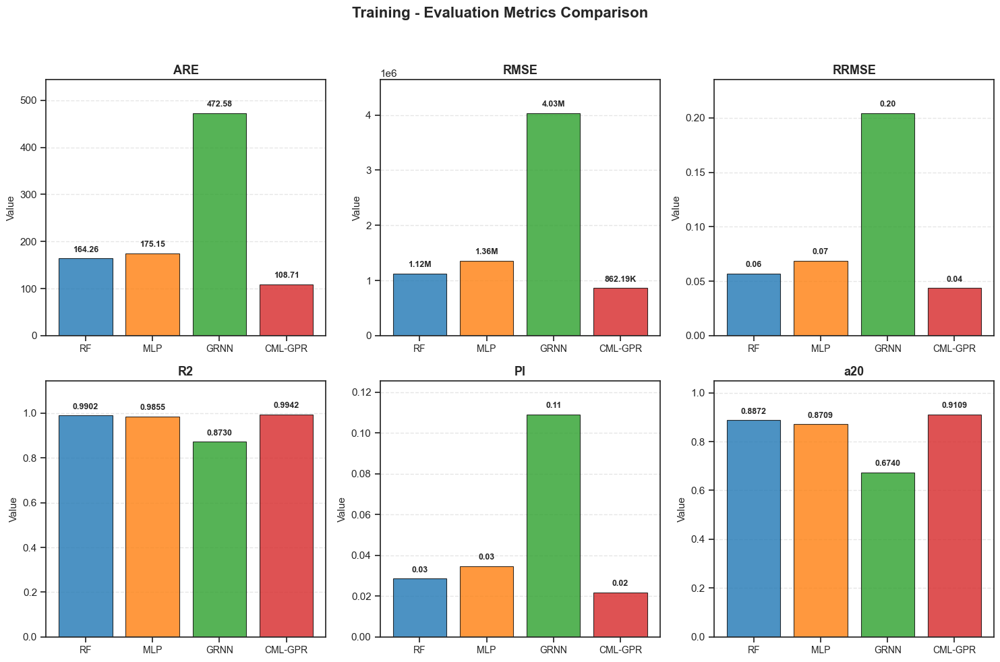

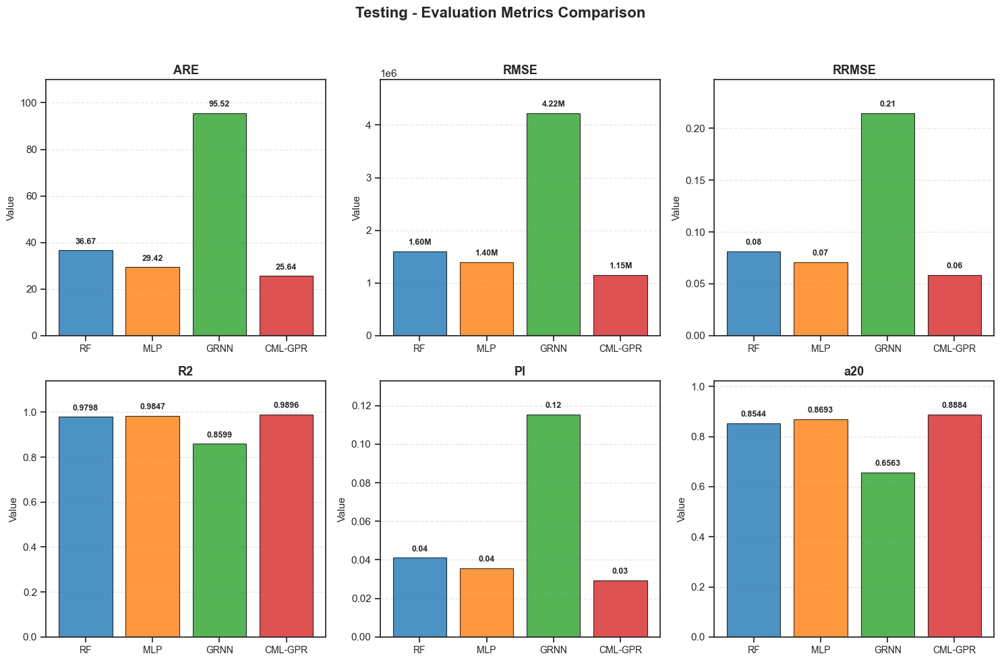

In [43]:
train_metrics = {
    'ARE': [],
    'RMSE': [],
    'RRMSE': [],
    'R2': [],
    'PI': [],
    'a20': []
}

for pred in train_preds:
    ARE, rmse, rrms, r2, PI, a20 = compute_metrics(y_train_orig, pred)
    train_metrics['ARE'].append(ARE)
    train_metrics['RMSE'].append(rmse)
    train_metrics['RRMSE'].append(rrms)
    train_metrics['R2'].append(r2)
    train_metrics['PI'].append(PI)
    train_metrics['a20'].append(a20)

test_metrics = {
    'ARE': [],
    'RMSE': [],
    'RRMSE': [],
    'R2': [],
    'PI': [],
    'a20': []
}

for pred in test_preds:
    ARE, rmse, rrms, r2, PI, a20 = compute_metrics(y_test_orig, pred)
    test_metrics['ARE'].append(ARE)
    test_metrics['RMSE'].append(rmse)
    test_metrics['RRMSE'].append(rrms)
    test_metrics['R2'].append(r2)
    test_metrics['PI'].append(PI)
    test_metrics['a20'].append(a20)

def plot_metrics_bar(metrics_dict, models, title_prefix, save_path=None):
    metric_names = ['ARE', 'RMSE', 'RRMSE', 'R2', 'PI', 'a20']
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # RF, MELM, GRNN, CML-GPR
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for i, metric in enumerate(metric_names):
        ax = axes[i]
        values = metrics_dict[metric]
        bars = ax.bar(models, values, color=colors, edgecolor='black', linewidth=0.8, alpha=0.8)
        
        # Judul dan label
        ax.set_title(metric, fontsize=13, fontweight='bold')
        ax.set_ylabel('Value', fontsize=11)
        ax.grid(True, axis='y', linestyle='--', alpha=0.5)
        
        # Tambahkan nilai di atas batang
        for bar, val in zip(bars, values):
            if metric in ['R2', 'a20']:
    
                label = f'{val:.4f}'
            else:
                
                if metric == 'RMSE' and val > 1e6:
                    label = f'{val/1e6:.2f}M'
                elif metric == 'RMSE' and val > 1e3:
                    label = f'{val/1e3:.2f}K'
                else:
                    label = f'{val:.2f}'
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02 * max(values),
                    label, ha='center', va='bottom', fontsize=9, fontweight='bold')
        
        
        ax.set_ylim(0, max(values) * 1.15)
        ax.tick_params(axis='x', labelsize=10)
    
    plt.suptitle(f'{title_prefix} - Evaluation Metrics Comparison', fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


plot_metrics_bar(train_metrics, models, 'Training', save_path='training_metrics_bar.png')


plot_metrics_bar(test_metrics, models, 'Testing', save_path='testing_metrics_bar.png')

RF: MOE=1245965.4660, SD=1007732.1590, SE=15477.9489, ME=30336.7799, WCB=60673.5599
MLP: MOE=1028079.5645, SD=944612.6441, SE=14508.4844, ME=28436.6294, WCB=56873.2587
GRNN: MOE=3481033.2115, SD=2393635.3146, SE=36764.2978, ME=72058.0237, WCB=144116.0474
CML-GPR: MOE=884775.1898, SD=736692.5606, SE=11315.0005, ME=22177.4009, WCB=44354.8018


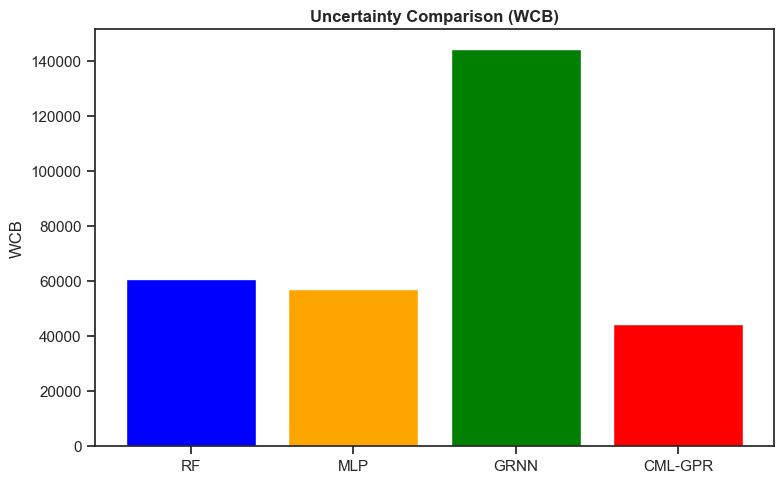

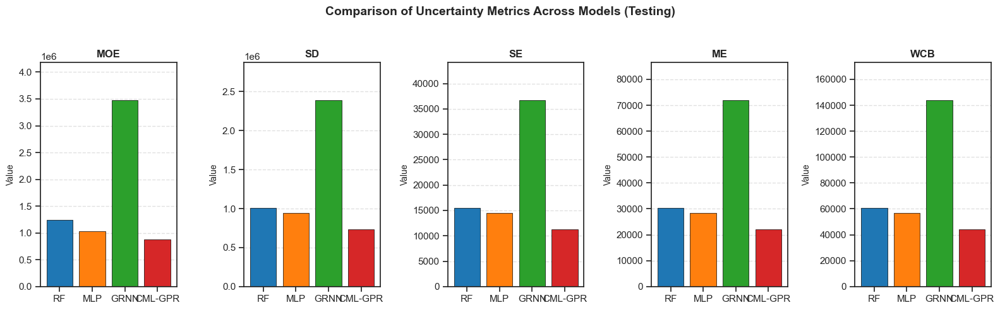

In [34]:
def uncertainty_metrics(y_true, y_pred):
    errors = np.abs(y_true - y_pred)
    MOE = np.mean(errors)
    SD = np.std(errors, ddof=1)
    SE = SD / np.sqrt(len(errors))
    ME = 1.96 * SE
    LB = MOE - ME
    UB = MOE + ME
    WCB = UB - LB
    return MOE, SD, SE, ME, LB, UB, WCB

wcb_values = []
for name, pred in zip(models, test_preds):
    MOE, SD, SE, ME, LB, UB, WCB = uncertainty_metrics(y_test_orig, pred)
    print(f"{name}: MOE={MOE:.4f}, SD={SD:.4f}, SE={SE:.4f}, ME={ME:.4f}, WCB={WCB:.4f}")
    wcb_values.append(WCB)

plt.figure(figsize=(8,5))
plt.bar(models, wcb_values, color=['blue','orange','green','red'])
plt.ylabel('WCB')
plt.title('Uncertainty Comparison (WCB)', fontweight='bold')
plt.tight_layout()
plt.show()

models = ['RF', 'MLP', 'GRNN', 'CML-GPR']
test_preds = [y_rf_test_orig, y_melm_test_orig, y_grnn_test_orig, y_cml_test_orig]

metrics_names = ['MOE', 'SD', 'SE', 'ME', 'WCB']
metrics_values = {name: [] for name in metrics_names}

for pred in test_preds:
    MOE, SD, SE, ME, LB, UB, WCB = uncertainty_metrics(y_test_orig, pred)
    metrics_values['MOE'].append(MOE)
    metrics_values['SD'].append(SD)
    metrics_values['SE'].append(SE)
    metrics_values['ME'].append(ME)
    metrics_values['WCB'].append(WCB)

# --- Buat figure dengan 1 baris 5 kolom ---
fig, axes = plt.subplots(1, 5, figsize=(16, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # warna untuk RF, MLP, GRNN, CML-GPR

for i, metric in enumerate(metrics_names):
    ax = axes[i]
    values = metrics_values[metric]
    bars = ax.bar(models, values, color=colors, edgecolor='black', linewidth=0.5)
    
    # Judul dan label
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel('Value', fontsize=10)
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    
    # Atur rentang y agar nilai terbaca
    ax.set_ylim(0, max(values) * 1.2)

plt.suptitle('Comparison of Uncertainty Metrics Across Models (Testing)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('uncertainty_metrics_barchart.png', dpi=300)
plt.show()

# **8. Cross Plot Visualization**

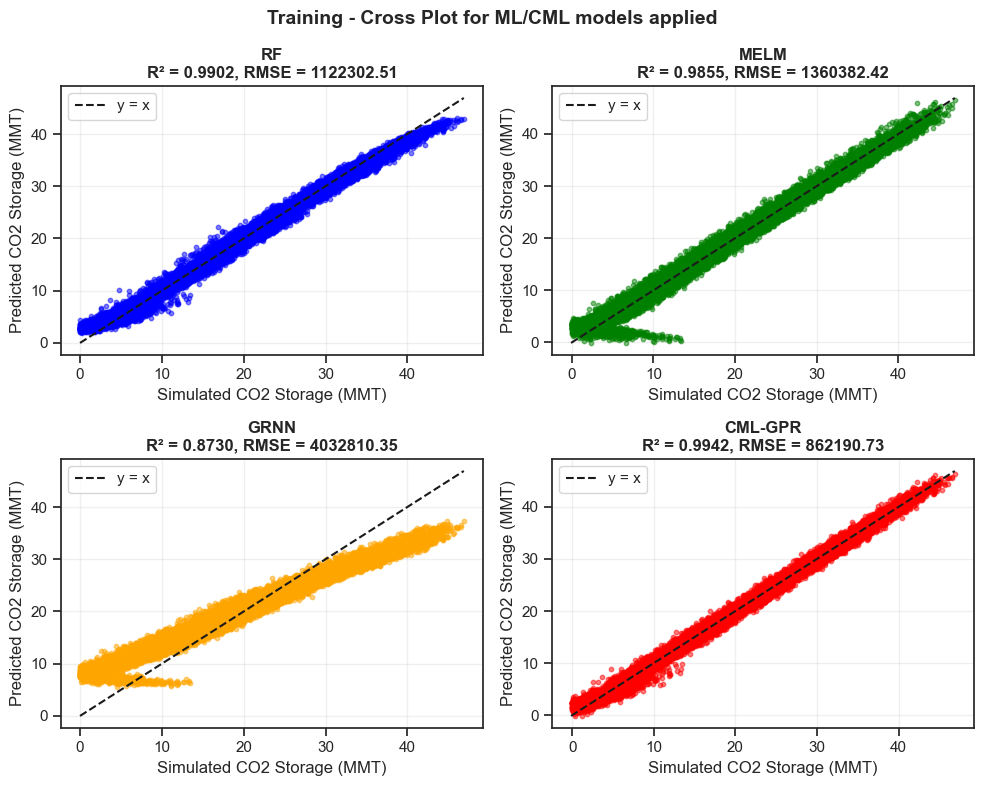

In [35]:
import matplotlib.ticker as ticker

model_colors = {
    'RF': 'blue',
    'MELM': 'green',
    'GRNN': 'orange',
    'CML-GPR': 'red'
}

train_data = {
    'RF': y_rf_train_orig,
    'MELM': y_melm_train_orig,
    'GRNN': y_grnn_train_orig,
    'CML-GPR': y_cml_train_orig
}

test_data = {
    'RF': y_rf_test_orig,
    'MELM': y_melm_test_orig,
    'GRNN': y_grnn_test_orig,
    'CML-GPR': y_cml_test_orig
}

def plot_cross_plot_grid(y_true, y_pred_dict, model_names, colors, title_prefix, save_path=None):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()
    
    for i, (name, color) in enumerate(zip(model_names, colors)):
        ax = axes[i]
        y_pred = y_pred_dict[name]
        
        # Scatter plot
        ax.scatter(y_true / 1e6, y_pred / 1e6, alpha=0.5, s=10, color=color)
        
        # Garis y=x
        min_val = min(y_true.min(), y_pred.min()) / 1e6
        max_val = max(y_true.max(), y_pred.max()) / 1e6
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='y = x')
        
        # Hitung metrik
        r2 = r2_score(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        
        # Label dan judul
        ax.set_xlabel('Simulated CO2 Storage (MMT)')
        ax.set_ylabel('Predicted CO2 Storage (MMT)')
        ax.set_title(f'{name}\nR² = {r2:.4f}, RMSE = {rmse:.2f}')
        fontweight = 'bold' 
        ax.title.set_fontweight(fontweight)
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        # Format sumbu agar tidak scientific notation
        ax.xaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=False))
        ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=False))
        ax.ticklabel_format(style='plain', axis='both')
    
    plt.suptitle(f'{title_prefix} - Cross Plot for ML/CML models applied', fontsize=14, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

model_names = ['RF', 'MELM', 'GRNN', 'CML-GPR']
colors = [model_colors[name] for name in model_names]

plot_cross_plot_grid(
    y_true=y_train_orig,
    y_pred_dict=train_data,
    model_names=model_names,
    colors=colors,
    title_prefix='Training',
)

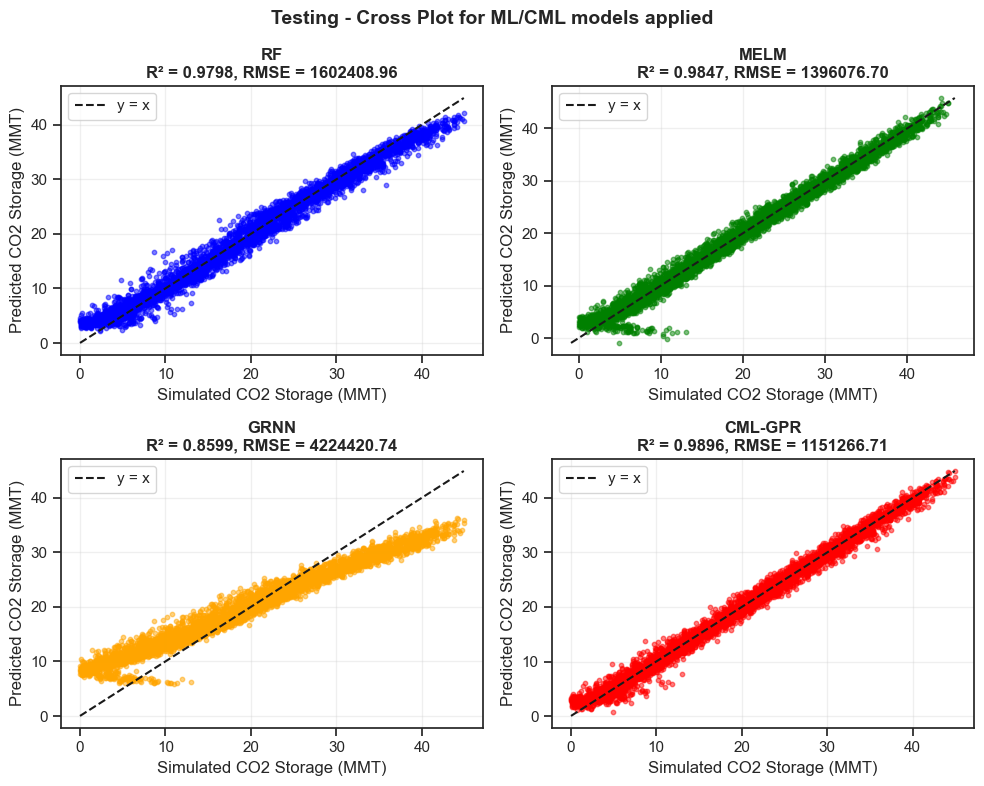

In [36]:
plot_cross_plot_grid(
    y_true=y_test_orig,
    y_pred_dict=test_data,
    model_names=model_names,
    colors=colors,
    title_prefix='Testing',
)

# **9. Cumulative Frequency Plot**

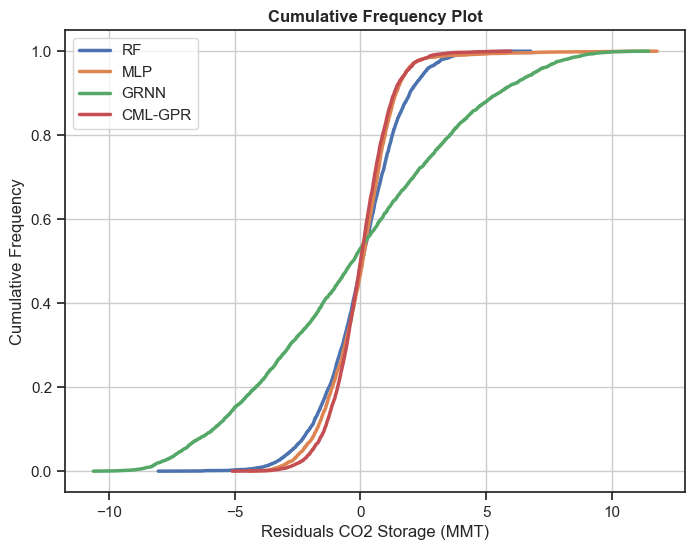

In [37]:
def plot_cumulative_residual(y_true, y_pred_list, model_names, title, save_path=None):
    plt.figure(figsize=(8,6))
    for y_pred, name in zip(y_pred_list, model_names):
        # Residual dibagi 1e6 agar sumbu x dalam jutaan
        residuals = (y_true - y_pred) / 1e6
        sorted_res = np.sort(residuals)
        cum_prob = np.arange(1, len(sorted_res)+1) / len(sorted_res)
        plt.plot(sorted_res, cum_prob, label=name, linewidth=2.5) 
    plt.xlabel('Residuals CO2 Storage (MMT)')
    plt.ylabel('Cumulative Frequency')
    plt.title(title, fontweight = 'bold')
    plt.legend()
    plt.grid(True)
    if save_path:
        plt.savefig(save_path)
    plt.show()

# Panggil untuk data testing
plot_cumulative_residual(y_test_orig, test_preds, models, 
                         'Cumulative Frequency Plot', 
                       )

# **10. SHAP Analysis**

### **10.1 SHAP Plot for RF**

100%|===================| 4223/4239 [04:22<00:00]        

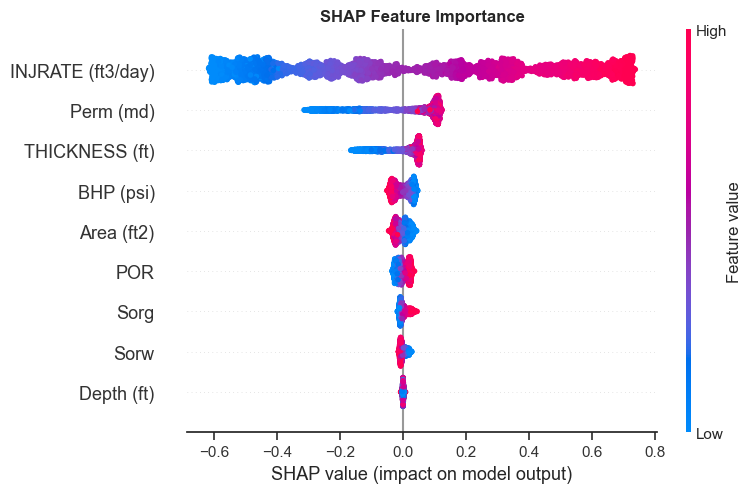

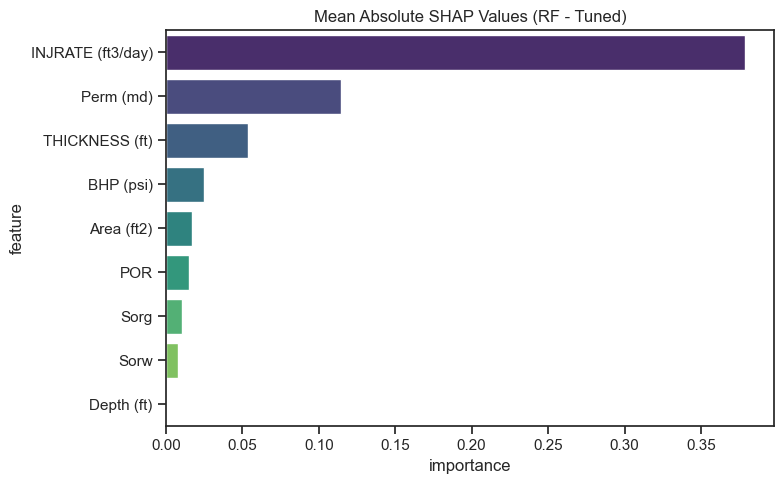

In [38]:
import shap
explainer = shap.TreeExplainer(rf_model, X_train_scaled)
shap_values = explainer.shap_values(X_test_scaled)
plt.figure(figsize=(10,6))
shap.summary_plot(shap_values, X_test_scaled, feature_names=feature_names, show=False)
plt.title('SHAP Feature Importance', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary_tuned.png')
plt.show()

shap_mean_abs = np.mean(np.abs(shap_values), axis=0)
shap_importance = pd.DataFrame({'feature': feature_names, 'importance': shap_mean_abs}).sort_values('importance', ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(data=shap_importance, x='importance', y='feature', palette='viridis')
plt.title('Mean Absolute SHAP Values (RF - Tuned)')
plt.tight_layout()
plt.savefig('shap_bar_tuned.png')
plt.show()

### **10.2 SHAP Plot for CML-GPR**

Menghitung SHAP values untuk CML-GPR...


  0%|          | 0/50 [00:00<?, ?it/s]

Selesai.


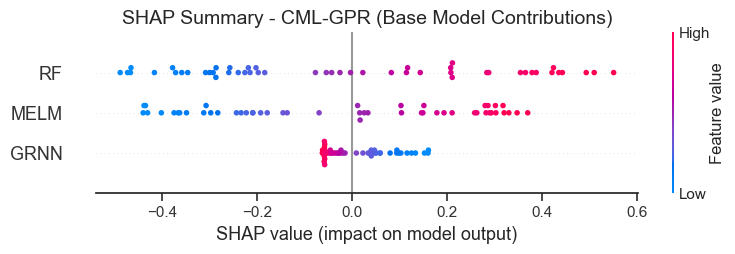

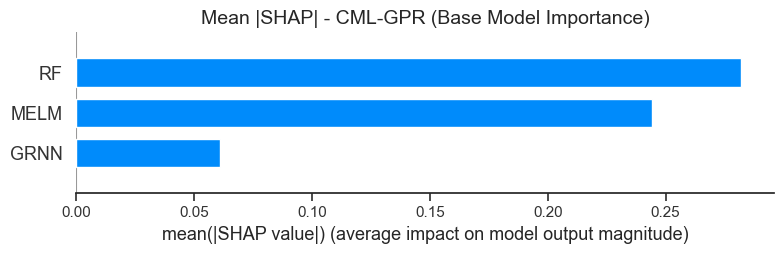


===== MEAN ABSOLUTE SHAP (3 BASE MODELS) =====
RF: 0.2819
MELM: 0.2444
GRNN: 0.0612


In [ ]:
n_background = min(50, X_gpr_train_scaled.shape[0])
n_test_sample = min(50, X_gpr_test_scaled.shape[0])

np.random.seed(42)
idx_bg = np.random.choice(X_gpr_train_scaled.shape[0], n_background, replace=False)
background = X_gpr_train_scaled[idx_bg]

idx_ts = np.random.choice(X_gpr_test_scaled.shape[0], n_test_sample, replace=False)
test_sample = X_gpr_test_scaled[idx_ts]

explainer = shap.KernelExplainer(gpr_model.predict, background)

print("Menghitung SHAP values untuk CML-GPR...")
shap_values = explainer.shap_values(test_sample)
print("Selesai.")

# shap_values adalah array (n_samples, 12)
shap_values_3 = shap_values[:, :3]  # ambil 3 kolom pertama
test_sample_3 = test_sample[:, :3]  # ambil 3 kolom pertama

# Nama fitur untuk 3 base model
meta_feature_names = ['RF', 'MELM', 'GRNN']


# 1. Summary plot (dot plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_3, test_sample_3, feature_names=meta_feature_names, show=False)
plt.title('SHAP Summary - CML-GPR (Base Model Contributions)', fontsize=14)
plt.tight_layout()
plt.savefig('shap_cml_gpr_summary_3features.png', dpi=300)
plt.show()

# 2. Bar plot (mean absolute SHAP)
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values_3, test_sample_3, feature_names=meta_feature_names, plot_type="bar", show=False)
plt.title('Mean |SHAP| - CML-GPR (Base Model Importance)', fontsize=14)
plt.tight_layout()
plt.savefig('shap_cml_gpr_bar_3features.png', dpi=300)
plt.show()

# 3. Tabel mean absolute SHAP (cetak di terminal)
mean_abs_shap = np.mean(np.abs(shap_values_3), axis=0)
print("\nMEAN ABSOLUTE SHAP (3 BASE MODELS)")
for name, val in zip(meta_feature_names, mean_abs_shap):
    print(f"{name}: {val:.4f}")


# **11. Scoring System**


SCORES TRAINING:
RF: 18
MLP: 12
GRNN: 6
CML-GPR: 24

SCORES TESTING:
RF: 12
MLP: 18
GRNN: 6
CML-GPR: 24

TOTAL SCORES (TRAINING + TESTING)
RF: 30
MLP: 30
GRNN: 12
CML-GPR: 48


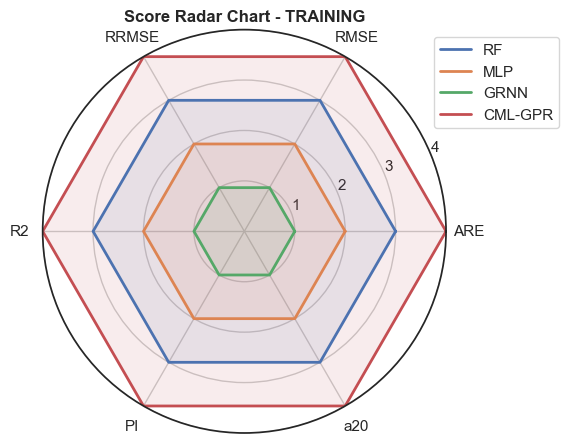

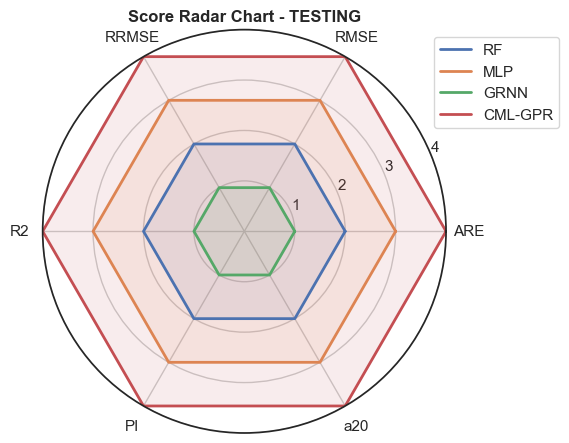

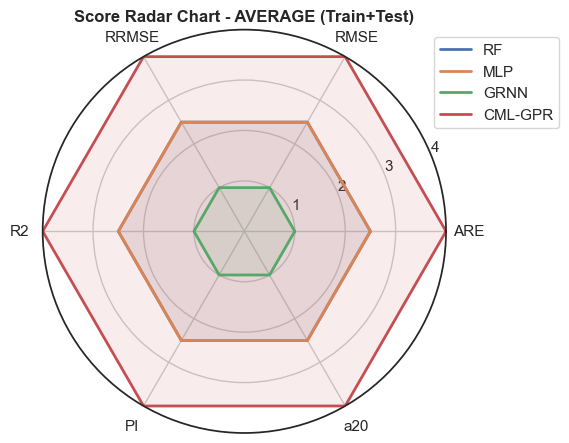

In [ ]:
def assign_scores(metric_values, higher_better=False):
    """
    Memberi skor 1-4 berdasarkan peringkat metrik.
    higher_better=True untuk R2 dan a20-index.
    """
    sorted_indices = np.argsort(metric_values) if not higher_better else np.argsort(-np.array(metric_values))
    scores = np.zeros(len(metric_values), dtype=int)
    for rank, idx in enumerate(sorted_indices):
        scores[idx] = rank + 1
    return 5 - scores  # agar skor 4 untuk peringkat 1 (terbaik)

def compute_scores(y_true, y_pred_list, model_names, metrics, dataset_name):
    """
    Hitung skor untuk satu dataset (training atau testing).
    """
    all_metrics = []
    for pred in y_pred_list:
        ARE, rmse, rrms, r2, PI, a20 = compute_metrics(y_true, pred)
        all_metrics.append([ARE, rmse, rrms, r2, PI, a20])
    all_metrics = np.array(all_metrics)
    
    score_matrix = np.zeros((len(model_names), len(metrics)), dtype=int)
    for j, m in enumerate(metrics):
        higher_better = m in ['R2', 'a20']
        score_matrix[:, j] = assign_scores(all_metrics[:, j], higher_better)
    
    total_scores = np.sum(score_matrix, axis=1)
    print(f"\nSCORES {dataset_name}:")
    for i, name in enumerate(model_names):
        print(f"{name}: {total_scores[i]}")
    
    return total_scores, score_matrix

metrics = ['ARE', 'RMSE', 'RRMSE', 'R2', 'PI', 'a20']
models = ['RF', 'MLP', 'GRNN', 'CML-GPR']

# Prediksi untuk training dan testing (dalam skala asli)
train_preds = [y_rf_train_orig, y_melm_train_orig, y_grnn_train_orig, y_cml_train_orig]
test_preds = [y_rf_test_orig, y_melm_test_orig, y_grnn_test_orig, y_cml_test_orig]

# Hitung skor training
train_scores, train_score_matrix = compute_scores(
    y_train_orig, train_preds, models, metrics, "TRAINING"
)

# Hitung skor testing
test_scores, test_score_matrix = compute_scores(
    y_test_orig, test_preds, models, metrics, "TESTING"
)

# Total skor (training + testing)
total_scores = train_scores + test_scores
print("\nTOTAL SCORES (TRAINING + TESTING)")
for i, name in enumerate(models):
    print(f"{name}: {total_scores[i]}")

# Radar Chart untuk skor training
from math import pi
def plot_radar(score_matrix, model_names, metrics, title, save_path=None):
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(6,6), subplot_kw=dict(polar=True))
    for i, name in enumerate(model_names):
        values = score_matrix[i, :].tolist()
        values += values[:1]
        ax.plot(angles, values, label=name, linewidth=2)
        ax.fill(angles, values, alpha=0.1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics)
    ax.set_yticks([1,2,3,4])
    ax.set_ylim(0,4)
    ax.set_title(title, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.3,1.0))
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

# Plot radar untuk training dan testing
plot_radar(train_score_matrix, models, metrics, 'Score Radar Chart - TRAINING', 'radar_training.png')
plot_radar(test_score_matrix, models, metrics, 'Score Radar Chart - TESTING', 'radar_testing.png')

avg_score_matrix = (train_score_matrix + test_score_matrix) / 2
plot_radar(avg_score_matrix, models, metrics, 'Score Radar Chart - AVERAGE (Train+Test)', 'radar_average.png')

RF: MOE=1245965.4660, SD=1007732.1590, SE=15477.9489, ME=30336.7799, WCB=60673.5599
MLP: MOE=1028079.5645, SD=944612.6441, SE=14508.4844, ME=28436.6294, WCB=56873.2587
GRNN: MOE=3481033.2115, SD=2393635.3146, SE=36764.2978, ME=72058.0237, WCB=144116.0474
CML-GPR: MOE=884775.1898, SD=736692.5606, SE=11315.0005, ME=22177.4009, WCB=44354.8018


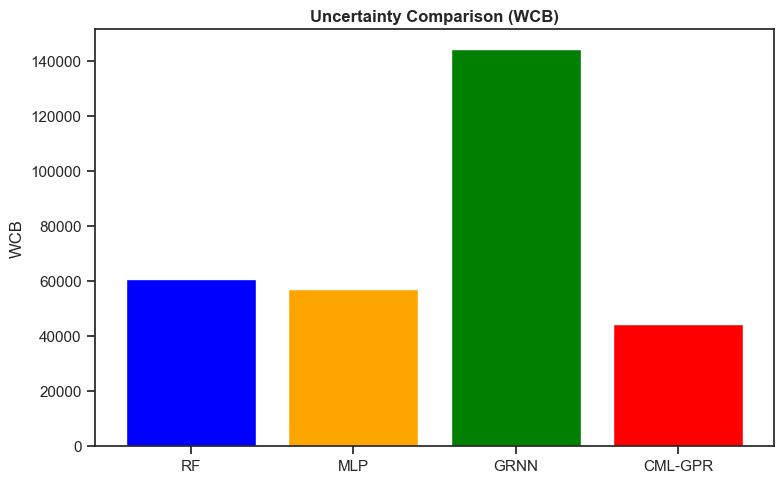

In [42]:
def uncertainty_metrics(y_true, y_pred):
    errors = np.abs(y_true - y_pred)
    MOE = np.mean(errors)
    SD = np.std(errors, ddof=1)
    SE = SD / np.sqrt(len(errors))
    ME = 1.96 * SE
    LB = MOE - ME
    UB = MOE + ME
    WCB = UB - LB
    return MOE, SD, SE, ME, LB, UB, WCB

wcb_values = []
for name, pred in zip(models, test_preds):
    MOE, SD, SE, ME, LB, UB, WCB = uncertainty_metrics(y_test_orig, pred)
    print(f"{name}: MOE={MOE:.4f}, SD={SD:.4f}, SE={SE:.4f}, ME={ME:.4f}, WCB={WCB:.4f}")
    wcb_values.append(WCB)

plt.figure(figsize=(8,5))
plt.bar(models, wcb_values, color=['blue','orange','green','red'])
plt.ylabel('WCB')
plt.title('Uncertainty Comparison (WCB)', fontweight='bold')
plt.tight_layout()
plt.show()